# Cricketer Image Classification using CNN

This notebook uses the provided `cricketer_dataset.csv` file.

Classes:
- Virat Kohli
- Rohit Sharma
- Jasprit Bumrah
- Hardik Pandya
- MS Dhoni

The notebook includes:
- CSV loading
- Label encoding
- Reshaping flattened pixels into 128×128×3 images
- Normalization
- Train/test split
- Data augmentation
- CNN model
- Dropout
- Early stopping
- Accuracy/loss plots
- Classification report
- Confusion matrix
- Model and label encoder saving


In [1]:
# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    RandomFlip,
    RandomRotation,
    RandomZoom
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [2]:
# 2. Load the CSV dataset

df = pd.read_csv("cricketer_dataset.csv")

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (1500, 49153)


,0,1,2,3,4,5,6,7,8,9,...,49143,49144,49145,49146,49147,49148,49149,49150,49151,Target
0,54,63,66,54,63,66,55,63,66,55,...,37,64,67,34,57,59,32,54,55,Virat Kohli
1,0,0,0,0,0,0,0,0,0,0,...,1,3,2,4,4,7,6,5,9,Virat Kohli
2,18,16,15,17,15,14,16,14,13,16,...,107,115,122,102,103,104,99,97,95,Virat Kohli
3,22,16,99,22,17,86,23,20,60,23,...,60,40,47,63,39,40,65,38,37,Virat Kohli
4,199,82,51,199,84,54,199,87,60,200,...,240,233,231,241,234,230,241,235,230,Virat Kohli


In [3]:
# 3. Check class distribution

print(df["Target"].value_counts())


Target
Virat Kohli       300
Rohit Sharma      300
Jasprit Bumrah    300
Hardik Pandya     300
MS Dhoni          300
Name: count, dtype: int64


In [4]:
# 4. Separate input features and target

X = df.drop("Target", axis=1)
y = df["Target"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (1500, 49152)
y shape: (1500,)


In [5]:
# 5. Encode cricketer names into numbers

encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Classes:")
for i, name in enumerate(encoder.classes_):
    print(i, "=", name)


Classes:
0 = Hardik Pandya
1 = Jasprit Bumrah
2 = MS Dhoni
3 = Rohit Sharma
4 = Virat Kohli


In [6]:
# 6. Convert pixel data to NumPy float32

X = X.to_numpy(dtype=np.float32)

print("X shape before reshape:", X.shape)


X shape before reshape: (1500, 49152)


In [7]:
# 7. Reshape flattened pixels into images

X = X.reshape(-1, 128, 128, 3)

print("X shape after reshape:", X.shape)


X shape after reshape: (1500, 128, 128, 3)


In [8]:
# 8. Normalize pixel values from 0-255 to 0-1

X = X / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


Minimum pixel value: 0.0
Maximum pixel value: 1.0


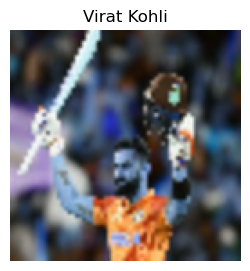

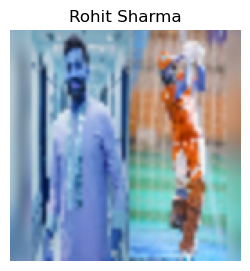

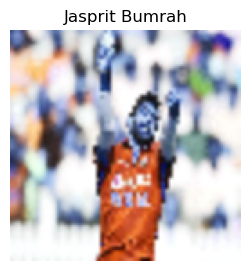

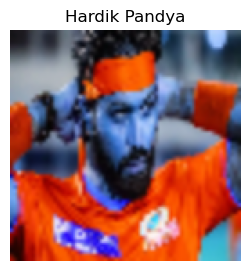

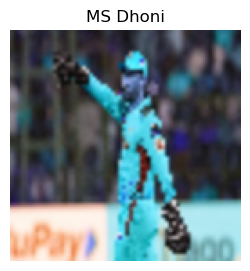

In [9]:
# 9. Display a few reconstructed images

for i in [0, 300, 600, 900, 1200]:
    plt.figure(figsize=(3, 3))
    plt.imshow(X[i])
    plt.title(encoder.inverse_transform([y[i]])[0])
    plt.axis("off")
    plt.show()


In [10]:
# 10. Train-test split

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("x_train:", x_train.shape)
print("x_test :", x_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


x_train: (1200, 128, 128, 3)
x_test : (300, 128, 128, 3)
y_train: (1200,)
y_test : (300,)


In [11]:
# 11. Data augmentation

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.05),
    RandomZoom(0.10)
])


In [12]:
# 12. Clear old Keras session before creating a fresh model

tf.keras.backend.clear_session()

num_classes = len(encoder.classes_)

print("Number of classes:", num_classes)



Number of classes: 5


In [13]:
# 13. Build CNN model

model = Sequential([
    Input(shape=(128, 128, 3)),

    data_augmentation,

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Dropout(0.30),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.50),

    Dense(num_classes, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 32768)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,194,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 14. Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [15]:
# 15. Early stopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


In [16]:
# 16. Train the CNN

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 23s 538ms/step - accuracy: 0.2692 - loss: 1.7539 - val_accuracy: 0.3067 - val_loss: 1.4774
Epoch 2/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 40s 498ms/step - accuracy: 0.3217 - loss: 1.4476 - val_accuracy: 0.3433 - val_loss: 1.4156
Epoch 3/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 501ms/step - accuracy: 0.3533 - loss: 1.4133 - val_accuracy: 0.3600 - val_loss: 1.3815
Epoch 4/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 506ms/step - accuracy: 0.3708 - loss: 1.3746 - val_accuracy: 0.3633 - val_loss: 1.3685
Epoch 5/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 518ms/step - accuracy: 0.3633 - loss: 1.3728 - val_accuracy: 0.3533 - val_loss: 1.3673
Epoch 6/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 514ms/step - accuracy: 0.3850 - loss: 1.3663 - val_accuracy: 0.3700 - val_loss: 1.3741
Epoch 7/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 518ms/step - accuracy: 0.3958 - loss: 1.3360 - val_accuracy: 0.4133 - val_loss: 1.3378
Epoch 8/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 539ms/step - accuracy: 0.4125 - loss: 1.3164 - val_accu

In [17]:
# 17. Evaluate the model

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


Test Loss: 1.275256633758545
Test Accuracy: 0.5066666603088379


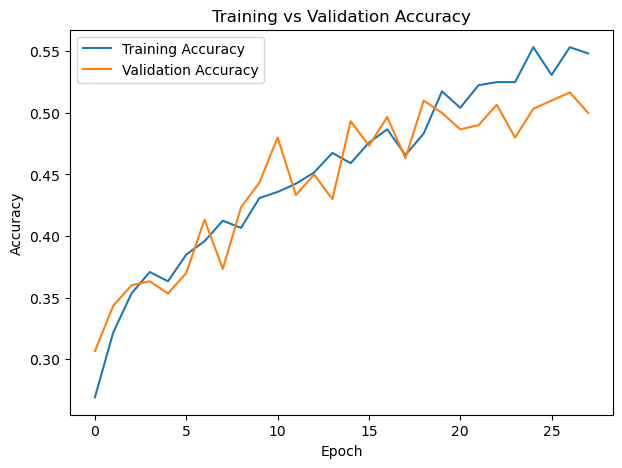

In [18]:
# 18. Plot training and validation accuracy

plt.figure(figsize=(7, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()


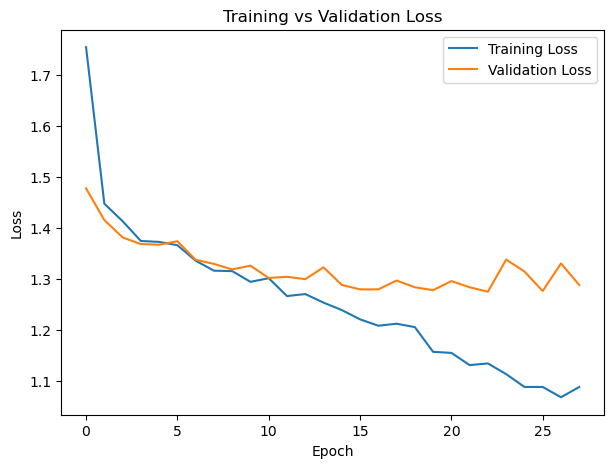

In [19]:
# 19. Plot training and validation loss

plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()


In [20]:
# 20. Make predictions on test data

y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.5066666666666667


In [21]:
# 21. Show first 10 actual vs predicted cricketers

for i in range(10):
    actual_name = encoder.inverse_transform([y_test[i]])[0]
    predicted_name = encoder.inverse_transform([y_pred[i]])[0]

    print(
        "Actual:", actual_name,
        "| Predicted:", predicted_name
    )


Actual: Jasprit Bumrah | Predicted: Jasprit Bumrah
Actual: Jasprit Bumrah | Predicted: Jasprit Bumrah
Actual: Rohit Sharma | Predicted: Rohit Sharma
Actual: Virat Kohli | Predicted: Virat Kohli
Actual: Virat Kohli | Predicted: Virat Kohli
Actual: Rohit Sharma | Predicted: Rohit Sharma
Actual: Virat Kohli | Predicted: Rohit Sharma
Actual: Hardik Pandya | Predicted: Hardik Pandya
Actual: Jasprit Bumrah | Predicted: Jasprit Bumrah
Actual: Virat Kohli | Predicted: Virat Kohli


In [22]:
# 22. Classification report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_
    )
)


                precision    recall  f1-score   support

 Hardik Pandya       0.42      0.37      0.39        60
Jasprit Bumrah       0.51      0.65      0.57        60
      MS Dhoni       0.93      0.65      0.76        60
  Rohit Sharma       0.37      0.60      0.46        60
   Virat Kohli       0.48      0.27      0.34        60

      accuracy                           0.51       300
     macro avg       0.54      0.51      0.51       300
  weighted avg       0.54      0.51      0.51       300



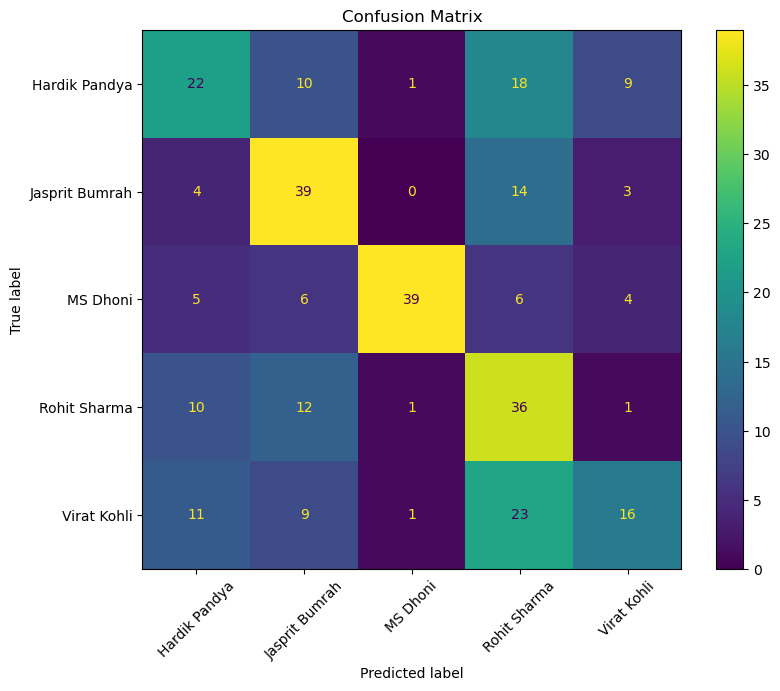

In [23]:
# 23. Confusion matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()


In [24]:
# 24. Show prediction distribution

unique, counts = np.unique(y_pred, return_counts=True)

for class_id, count in zip(unique, counts):
    print(
        encoder.inverse_transform([class_id])[0],
        ":",
        count
    )


Hardik Pandya : 52
Jasprit Bumrah : 76
MS Dhoni : 42
Rohit Sharma : 97
Virat Kohli : 33


In [25]:
# 25. Save trained CNN model

model.save("cricketer_model.keras")

print("Model saved as cricketer_model.keras")


Model saved as cricketer_model.keras


In [26]:
# 26. Save label encoder

joblib.dump(encoder, "label_encoder.pkl")

print("Label encoder saved as label_encoder.pkl")


Label encoder saved as label_encoder.pkl


In [27]:
# 27. Verify saved label encoder

test_encoder = joblib.load("label_encoder.pkl")

print("Saved classes:", test_encoder.classes_)


Saved classes: ['Hardik Pandya' 'Jasprit Bumrah' 'MS Dhoni' 'Rohit Sharma' 'Virat Kohli']


## Important

Your earlier model showed severe overfitting:
- Training accuracy was around 97%
- Validation/test accuracy was around 27%

This version adds:
- Data augmentation
- Dropout
- Early stopping

Run the notebook from top to bottom. After training, compare the new validation and test accuracy with the old 27% result.
